# Solutions: Chapter 18, Exploratory Data Analysis

Worked solutions to the exercises at the end of Chapter 18 of *Python for Data Science* by Vamsi Krishna Kandala. Try each exercise on your own first. Run the code yourself with the notebook [`ch18_solutions.ipynb`](ch18_solutions.ipynb) or the script `ch18_solutions.py`.

Numbers that depend on random data or library versions may differ slightly on your computer; the conclusions should not.


In [ ]:
# Setup: recreates the context these solutions build on (from the chapter).
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
flats = pd.read_csv("data/apartments.csv", parse_dates=["listed"])
flats.loc[flats["sqft"] > 4000, "sqft"] = (
    flats.loc[flats["sqft"] > 4000, "sqft"] // 10)
flats["per_sqft"] = flats["rent"] / flats["sqft"]


def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "distinct": df.nunique(),
        "example": df.iloc[0].astype(str).str[:10],
    })

The solutions start from the chapter's apartment data, with the size typo fixed and the `per_sqft` column, and its `profile` function.

## Exercise 18.1

*Run `profile` on `shop_orders_raw.csv` from Chapter 11, and list the problems it reveals at a glance.*

In [ ]:
raw = pd.read_csv("data/shop_orders_raw.csv")
print(profile(raw))
print(len(raw), "rows")

                 dtype  missing  distinct     example
order_id           str        0      1100    HC-10001
order_date         str        7       182  2026-02-16
customer_id        str        0       304       C0155
state              str       11        21        N.Y.
product            str        0         6  Decaf Swis
bag_size           str        0         3        500g
quantity       float64        5         7         2.0
unit_price         str        4        25      $26.10
shipping_days  float64       66         7         4.0
status             str        0         8   delivered
rating         float64      520         7         5.0
1118 rows


Even this one table shows most of Chapter 11's work list: `order_id` has fewer distinct values than there are rows (duplicates); `quantity`, `shipping_days` and `rating` are floats where whole numbers are expected (missing values); `unit_price` and `order_date` are text; `state` has 21 distinct values and `status` 8, more than the real ones; and six columns have gaps. What the profile can't show is which values are wrong, such as the 999-bag order; that needs `describe` and a look at the extremes.

## Exercise 18.2

*Draw the distribution of `days_on_market`, and say whether the mean or the median describes a typical listing better, and why.*

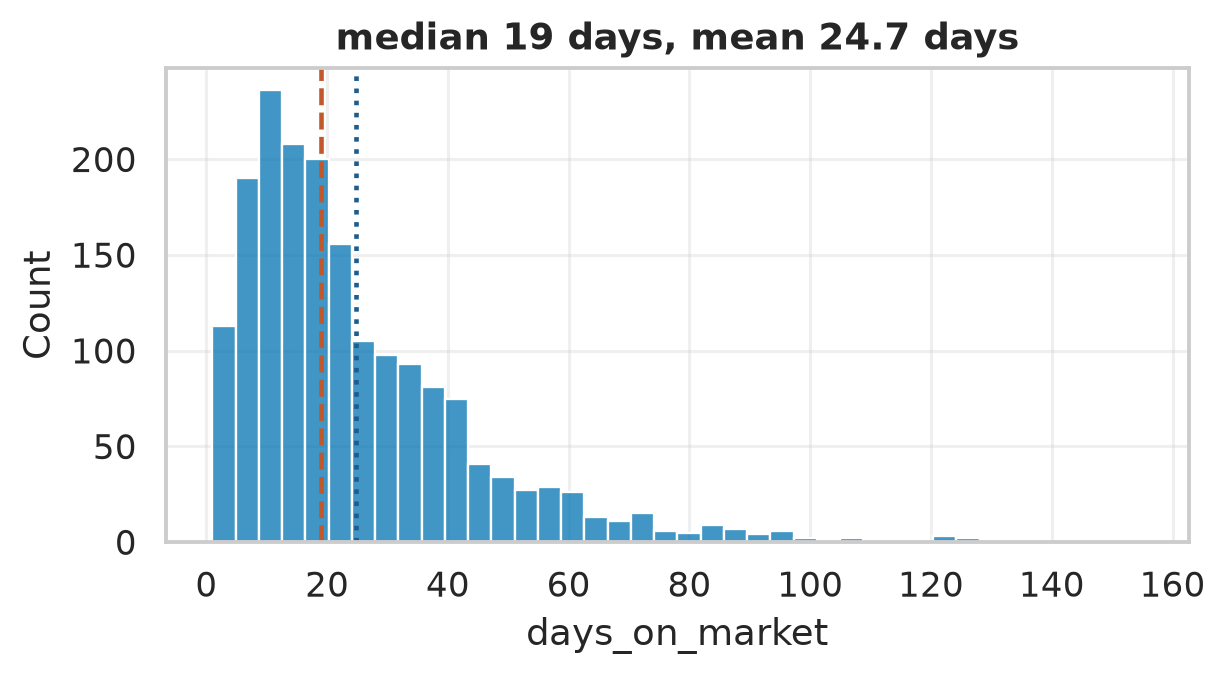

In [ ]:
days = flats["days_on_market"]
fig, ax = plt.subplots(figsize=(6, 2.8))
sns.histplot(days, bins=40, ax=ax)
ax.axvline(days.median(), color="#c0582b", ls="--")
ax.axvline(days.mean(), color="#1d5c8c", ls=":")
ax.set_title(f"median {days.median():.0f} days, mean "
             f"{days.mean():.1f} days")
plt.show()

*Days on the market, with the median (dashed) and the mean (dotted).*

The distribution is right-skewed: most apartments rent within a month, and a long tail takes two to five months. The tail pulls the mean, about 25 days, above the median, 19 days. The median describes a typical listing better: half of the listings rent faster than it, half slower. The mean is still useful for totals, such as the number of vacant apartment-days in a year.

## Exercise 18.3

*How much more do apartments with in-unit laundry rent for than those without, per square foot? Compare citywide and within districts.*

In [ ]:
city = flats.groupby("laundry")["per_sqft"].median()
print((city / city["none"] - 1).mul(100).round(1))
by_district = flats.pivot_table(index="district", columns="laundry",
                                values="per_sqft", aggfunc="median")
premium = (by_district["in unit"] / by_district["none"] - 1) * 100
print(premium.round(1).sort_values())

laundry
in building     3.2
in unit        10.9
none            0.0
Name: per_sqft, dtype: float64
district
North      6.3
Harbor     6.5
Central    7.1
East       8.4
West       9.3
South      9.5
dtype: float64


Citywide, in-unit laundry goes with rents about 11% higher per square foot than no laundry. Within districts, the premium is between about 6% and 10%, which is close: unlike building age, laundry isn't tied to location, so the citywide figure isn't distorted by a confounder. A premium of this size is roughly what an extra $110 a month on a typical apartment means.

## Exercise 18.4

*Draw a scatter chart of rent per square foot against distance from downtown, colored by district. Is distance a separate effect, or just another way of saying "district"?*

district
Central   -0.07
East      -0.35
Harbor    -0.07
North     -0.38
South     -0.49
West      -0.40
Name: distance_km, dtype: float64


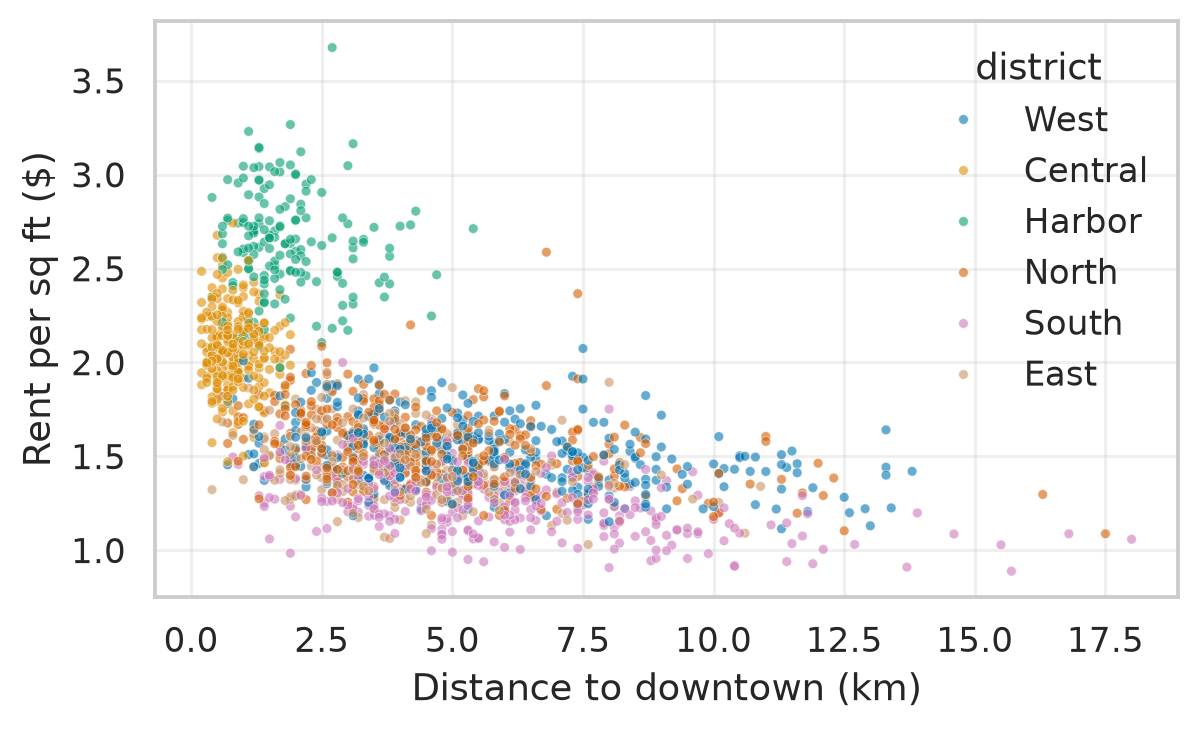

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.4))
sns.scatterplot(data=flats, x="distance_km", y="per_sqft",
                hue="district", s=10, alpha=0.6, ax=ax)
ax.set_xlabel("Distance to downtown (km)")
ax.set_ylabel("Rent per sq ft ($)")
plt.show()
within = flats.groupby("district")[["distance_km", "per_sqft"]].corr()
print(within.xs("per_sqft", level=1)["distance_km"].round(2))

*Rent per square foot against distance from downtown, colored by district.*

The districts form overlapping clouds at different distances, and the overall downward slope is partly the difference between districts. But within four of the six districts, the correlation is clearly negative too, between -0.35 and -0.49: apartments farther from downtown are cheaper even within the same district. In compact Central and Harbor, where every apartment is close to downtown, it is near zero. Distance is a separate effect, smaller than the district's but real. `xs` selects one level of the MultiIndex returned by the grouped `corr`.

## Exercise 18.5

*Find the month of the year with the most listings, and check whether apartments listed in that month rent faster or slower than in others.*

In [ ]:
month = flats["listed"].dt.month
per_month = flats.groupby(month).agg(
    listings=("listing_id", "count"),
    median_days=("days_on_market", "median"))
print(per_month)

        listings  median_days
listed                       
1             72         24.0
2             91         19.0
3            151         19.0
4            149         20.0
5            186         22.0
6            198         20.0
7            239         18.0
8            204         19.0
9            154         19.5
10           134         20.5
11           124         18.0
12            98         17.0


July has the most listings, as rental markets usually do in summer, when people move between school years. The median time to rent changes little from month to month, between 17 and 24 days, and July's 18 days is among the fastest, so more listings in summer seem to meet more renters too. Differences of a few days between months are within the noise of a hundred or two listings each.

## Exercise 18.6

*Compute the Spearman correlation of the numeric columns. Where does it differ most from the Pearson correlation, and why?*

In [ ]:
nums = ["rent", "sqft", "per_sqft", "year_built", "distance_km",
        "days_on_market"]
pearson = flats[nums].corr()
spearman = flats[nums].corr(method="spearman")
gap = (spearman - pearson).abs().stack()
gap = gap[gap.index.get_level_values(0) < gap.index.get_level_values(1)]
print(gap.sort_values(ascending=False).head(3).round(2))
print(f"rent vs sqft: Pearson {pearson.loc['rent', 'sqft']:.2f}, "
      f"Spearman {spearman.loc['rent', 'sqft']:.2f}")

per_sqft     rent          0.10
distance_km  per_sqft      0.08
per_sqft     year_built    0.07
dtype: float64
rent vs sqft: Pearson 0.75, Spearman 0.80


The **Spearman** correlation is the ordinary (Pearson) correlation of the *ranks* of the values: it measures whether one variable tends to rise when the other does, on a straight line or not, and a single extreme value can't dominate it. `stack` turns the matrix into one row per pair, and the filter keeps each pair once. The differences are small, at most 0.10, and the largest involve rent per square foot, a ratio with a long right tail. For rent and size, Spearman is a little stronger than Pearson, 0.80 against 0.75, because ranks aren't pulled around by the penthouse and the other expensive apartments.

## Exercise 18.7

*Apply the checklist to Riverton's 311 requests, and write a five-line summary with one chart.*

In [ ]:
raw = pd.read_csv("data/service_requests.csv", dtype=str)
raw.columns = raw.columns.str.lower().str.replace(" ", "_")
print(profile(raw)[["missing", "distinct"]])
fmt = "%m/%d/%Y %I:%M:%S %p"
created = pd.to_datetime(raw["created_date"], format=fmt)
closed = pd.to_datetime(raw["closed_date"], format=fmt)
days = (closed - created).dt.total_seconds() / 86400
print((days < 0).sum(), "negative durations,",
      (closed.dt.year == 1900).sum(), "closed in 1900")

                missing  distinct
unique_key            0      8330
created_date          0      8323
closed_date         126      7485
agency                0         7
complaint_type        0        32
incident_zip        249       820
district              0        21
status                0         4
channel               0         3
latitude            171      7166
longitude           171      7213
55 negative durations, 30 closed in 1900


Steps 2 and 3 find the problems Project 7 fixed: duplicate keys, 32 spellings of 10 complaint types, placeholder dates and impossible durations. For steps 4 to 6, the essential cleaning is in Project 7; here we only standardize the types quickly and look at days to close per agency, the question with the most at stake:

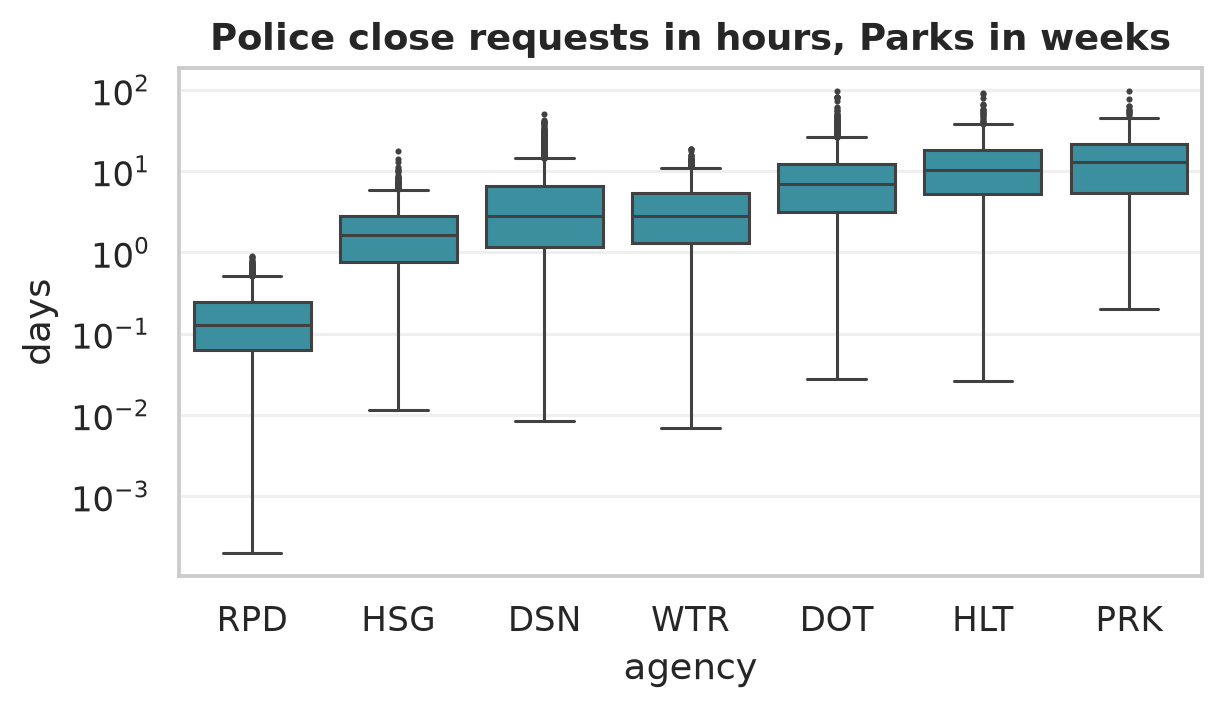

In [ ]:
kind = (raw["complaint_type"].str.lower().str.replace("–", "-")
        .str.replace(r"\s*([-/])\s*", r" \1 ", regex=True).str.strip())
ok = (days >= 0) & (closed.dt.year > 2000)
data = raw.assign(days=days, kind=kind)[ok].drop_duplicates(
    "unique_key")
order = data.groupby("agency")["days"].median().sort_values().index
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(data=data, x="agency", y="days", order=order,
            color="#2a9bb0", fliersize=1, ax=ax)
ax.set_yscale("log")
ax.set_title("Police close requests in hours, Parks in weeks")
plt.show()

*Days to close a 311 request by agency, on a log scale, ordered by the median.*

A five-line summary for a city manager:

1. Riverton received about 8,300 requests in 2025; the export has duplicates and placeholder dates, which are removed.

2. Noise, heat and hot water, missed collections and potholes are the most common complaints, each with its own season.

3. Requests per resident are about the same in every district.

4. Agencies' response times range from hours (police) to weeks (Parks and Forestry); see the chart.

5. Open question: street lights in the South district take twice as long as elsewhere (Project 7), which needs an explanation from the Department of Transportation.